In [ ]:
# tratamento de dados pt1
import pandas as pd

df = pd.read_csv('../dados/raw/DATA (1).csv', sep=',')

df.head()

,STUDENT ID,1,2,3,4,5,6,7,8,9,...,23,24,25,26,27,28,29,30,COURSE ID,GRADE
0,STUDENT1,2,2,3,3,1,2,2,1,1,...,1,1,3,2,1,2,1,1,1,1
1,STUDENT2,2,2,3,3,1,2,2,1,1,...,1,1,3,2,3,2,2,3,1,1
2,STUDENT3,2,2,2,3,2,2,2,2,4,...,1,1,2,2,1,1,2,2,1,1
3,STUDENT4,1,1,1,3,1,2,1,2,1,...,1,2,3,2,2,1,3,2,1,1
4,STUDENT5,2,2,1,3,2,2,1,3,1,...,2,1,2,2,2,1,2,2,1,1


In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145 entries, 0 to 144
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   STUDENT ID  145 non-null    object
 1   1           145 non-null    int64 
 2   2           145 non-null    int64 
 3   3           145 non-null    int64 
 4   4           145 non-null    int64 
 5   5           145 non-null    int64 
 6   6           145 non-null    int64 
 7   7           145 non-null    int64 
 8   8           145 non-null    int64 
 9   9           145 non-null    int64 
 10  10          145 non-null    int64 
 11  11          145 non-null    int64 
 12  12          145 non-null    int64 
 13  13          145 non-null    int64 
 14  14          145 non-null    int64 
 15  15          145 non-null    int64 
 16  16          145 non-null    int64 
 17  17          145 non-null    int64 
 18  18          145 non-null    int64 
 19  19          145 non-null    int64 
 20  20        

In [ ]:
# tratamento de dados pt2

df.drop(['STUDENT ID'], axis=1, inplace=True)

df.head()

,1,2,3,4,5,6,7,8,9,10,...,23,24,25,26,27,28,29,30,COURSE ID,GRADE
0,2,2,3,3,1,2,2,1,1,1,...,1,1,3,2,1,2,1,1,1,1
1,2,2,3,3,1,2,2,1,1,1,...,1,1,3,2,3,2,2,3,1,1
2,2,2,2,3,2,2,2,2,4,2,...,1,1,2,2,1,1,2,2,1,1
3,1,1,1,3,1,2,1,2,1,2,...,1,2,3,2,2,1,3,2,1,1
4,2,2,1,3,2,2,1,3,1,4,...,2,1,2,2,2,1,2,2,1,1


No aprendizado supervisionado, é imprescindível fornecer dois elementos fundamentais ao algoritmo: a matriz de atributos (features), que contém as variáveis independentes de cada instância, e o vetor gabarito (target), que armazena os resultados associados a cada uma delas. 

Diante dessa premissa, o tratamento prévio dos dados torna-se uma etapa crucial. Problemas comuns nessa fase incluem a presença de valores nulos ou ausentes (que exigem imputação estatística ou remoção), discrepâncias de grandezas entre variáveis (corrigidas via padronização) e atributos categóricos em formato de texto (que precisam ser convertidos em representações numéricas através de técnicas como One-Hot ou Label Encoding). 

A nossa primeira base de dados, entretanto, já foi obtida em um formato parcialmente pré-tratado: ela não continha dados faltantes e todas as variáveis qualitativas da matriz já haviam sido previamente mapeadas para números inteiros (Label Encoding). Ainda assim, durante a exploração, notamos a presença de variáveis puramente identificadoras, como STUDENT ID e COURSE ID. 

Nesse momento, levanta-se o questionamento de como manipular essas features, e a resposta toca em um fundamento da preparação de dados: não devemos utilizar atributos que não possuam qualquer relação de causa-efeito com o nosso alvo. O identificador de um aluno é um rótulo sequencial administrativo sem poder preditivo sobre a sua nota. Alimentar um algoritmo com esse tipo de dado apenas forçaria o modelo a tentar encontrar padrões matemáticos em ruídos. Desse modo, a decisão técnica mais assertiva foi eliminar essas colunas para garantir a consistência geométrica da matriz.

In [ ]:
# tratamento de dados pt3

X = df.drop(['COURSE ID', 'GRADE'], axis=1)

y = df['GRADE']

print('Formato de X:', X.shape)
print('Formato de Y:', y.shape)

Formato de X: (145, 30)
Formato de Y: (145,)


In [ ]:
# tratamento de dados pt4, separando a base em treinamento e teste.

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Tamanho do X (Treino):", X_train.shape)
print("Tamanho do gabarito y (Treino):", y_train.shape)
print("Tamanho do X (Teste):", X_test.shape)



Tamanho do X (Treino): (116, 30)
Tamanho do gabarito y (Treino): (116,)
Tamanho do X (Teste): (29, 30)


A próxima etapa consistiu no particionamento do dataset em subconjuntos de treino e de teste. A justificativa para essa divisão é fundamental: se entregássemos toda a matriz de atributos (X) e todo o vetor gabarito (y) para o algoritmo processar de uma só vez, seria impossível avaliar se ele de fato aprendeu a generalizar os padrões matemáticos ou se apenas "decorou" as respostas fornecidas — um colapso estatístico conhecido como overfitting (superajuste).

Para garantir um aprendizado robusto, a proporção padrão adotada na literatura (e aplicada no projeto com uma divisão de 80/20) destina a maior parcela dos dados ao treinamento. Isso ocorre porque os algoritmos, especialmente as Redes Neurais, necessitam do máximo de volume possível de exemplos para calcular o erro, ajustar seus pesos internos de forma iterativa e estabilizar o aprendizado. 

A porção menor (20%) é reservada exclusivamente para atuar como uma "prova final" cega, fornecendo instâncias inéditas para validar a eficácia real do modelo no mundo real. Adicionalmente, essa separação não é feita de forma sequencial, mas através de um sorteio aleatório. Essa aleatoriedade (controlada por uma semente fixa, o random_state, para garantir a reprodutibilidade do experimento) é crucial para evitar que o algoritmo desenvolva vieses de aprendizado caso a base de dados original estivesse ordenada por alguma característica específica, como turmas ou notas crescentes.

In [ ]:
# tratamento de dados pt5 pra corrigir eventuais erros de sequenciação de execução.

df = pd.read_csv('../dados/raw/DATA (1).csv', sep=',')

X = df.drop(['STUDENT ID', 'COURSE ID', 'GRADE'], axis=1)

y = df['GRADE']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Formato de X_train:", X_train.shape)

Formato de X_train: (116, 30)


O primeiro algoritmo testado foi uma Rede Neural Artificial, especificamente o Multi-Layer Perceptron (MLP). Em sala de aula, a fundamentação teórica baseou-se no Perceptron de Camada Única (Single-Layer Perceptron), cenário no qual introduzimos o conceito de taxa de aprendizado η. Esse hiperparâmetro compõe a fórmula de atualização de pesos, Δw = η.(y - ŷ).xi, em que o modelo calcula o erro — a diferença entre o gabarito real (y) e a previsão do modelo (ŷ) —, multiplicando-o pelo dado de entrada (xi) e pela taxa de aprendizado (η) para determinar a magnitude exata do ajuste necessário naquela conexão, visando minimizar o erro na iteração seguinte.

Do ponto de vista estrutural, o MLP diferencia-se do modelo de camada única pela introdução de Hidden Layers (camadas ocultas). Essas camadas intermediárias recebem as extrações de características mais simples feitas pela camada de entrada e as combinam de forma hierárquica, permitindo que a rede identifique interações complexas entre os atributos (por exemplo, a correlação entre o tipo de moradia, a posse de bolsa de estudos e o impacto simultâneo de ambos na nota final). A última camada consolida essas abstrações para fornecer a previsão final.

Na implementação através da biblioteca scikit-learn, o comportamento dessa arquitetura é governado por hiperparâmetros essenciais:

1. hidden_layer_sizes (A Arquitetura):
Define a quantidade de camadas ocultas e o número de neurônios alocados em cada uma. Não existe uma equação matemática universal para essa definição; o processo é iterativo e empírico. Contudo, a comunidade de Machine Learning adota heurísticas para estabelecer um ponto de partida seguro. Para dados tabulares estruturados, uma única camada oculta costuma possuir capacidade de aproximação suficiente para resolver o problema. A expansão para múltiplas camadas adentra o campo do Deep Learning, justificável apenas em domínios de altíssima dimensionalidade, como processamento de imagens ou linguagem natural.

Para o número de neurônios, a regra prática sugere um valor intermediário entre o tamanho da camada de entrada e o da camada de saída. Como a matriz de treino (X) possui 30 atributos e o vetor alvo (y) possui 1 saída, a média direciona a arquitetura inicial para 15 neurônios. Ignorar essa proporção e instanciar uma rede excessivamente grande gera três penalidades:

- Custo Computacional: Aumento exponencial no tempo de processamento e na alocação de memória.

- Overfitting (Superajuste): A inserção de centenas de neurônios adiciona milhares de pesos matemáticos desnecessários. Em bases de dados pequenas, esse excesso de capacidade faz com que a rede simplesmente memorize as particularidades e os ruídos da amostra de treino, perdendo a capacidade de generalizar regras para dados inéditos.

- Fome de Dados (Data Hunger): Para calibrar uma matriz de pesos gigantesca através do Δw, o algoritmo exige um volume massivo de instâncias para justificar essas conexões. Uma rede superdimensionada aplicada a um dataset curto sofre de instabilidade matemática; os pesos oscilam drasticamente e o modelo falha em convergir para uma solução confiável.

2. learning_rate_init (Taxa de Aprendizado)
Controla a magnitude do passo que o otimizador dá ao atualizar os pesos na direção do erro mínimo. Uma taxa excessivamente alta (ex: 0.1) acelera o treinamento, mas corre o risco de ultrapassar o ponto ideal de ajuste, impedindo a convergência. Por outro lado, uma taxa muito baixa (ex: 0.001) garante atualizações precisas e seguras, porém exige um tempo de processamento consideravelmente maior para que a rede alcance a estabilidade.

3. max_iter (Épocas de Treinamento)
Representa o limite de vezes que o algoritmo vai fazer iteração sobre o conjunto de dados completo para aplicar a atualização de pesos até que o erro estabilize (convirja). Na prática industrial, a comunidade costuma definir um número elevado de épocas aliado a técnicas de Early Stopping (parada antecipada). O Early Stopping monitora o erro em uma fração de validação isolada; se o modelo parar de melhorar após um determinado número de épocas, o treinamento é interrompido prematuramente, poupando processamento e mitigando o risco de overfitting causado por iterações excessivas.

4. activation (Função de Ativação)
No Perceptron de camada única, o neurônio utiliza funções matemáticas rígidas (como a função degrau (step function)) que limitam a saída a limiares binários de 0 ou 1, restringindo o modelo à resolução de problemas estritamente lineares. No MLP, empregamos funções matemáticas não-lineares e diferenciáveis, como a ReLU (Rectified Linear Unit) ou a função Logística (Sigmoide). A introdução dessas funções é o que confere à rede a capacidade de mapear fronteiras de decisão complexas e não-lineares, permitindo a separação geométrica de classes que não podem ser divididas por um simples hiperplano no espaço vetorial.

In [ ]:
# treinamento pt1 (MLP route)

from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

mlp = MLPClassifier(hidden_layer_sizes=(15,), max_iter=1000, random_state=42)

mlp.fit(X_train, y_train)

previsoes = mlp.predict(X_test)

acuracia = accuracy_score(y_test, previsoes)
print(f"Acurácia da Rede Neural: {acuracia * 100:.2f}%")


Acurácia da Rede Neural: 17.24%


c:\Users\enzol\OneDrive\Documentos\Python\IAtrabalho\.venv\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


Ao executar o modelo pela primeira vez, os resultados retornaram uma acurácia insatisfatória de apenas 17,24%, imediatamente acompanhada por um alerta do compilador: 

ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet. 

Após revisar a arquitetura do código e certificar a ausência de falhas lógicas na limpeza da base de dados, discutimos algumas hipóteses do porquê do erro.

Para investigar a raiz da falha de convergência, revisitamos os fundamentos do backpropagation e da descida do gradiente discutidos em sala de aula. Sabemos que a magnitude do ajuste de um peso Δw é diretamente proporcional ao valor do dado de entrada correspondente xi. Com essa premissa matemática em mente, realizamos uma inspeção descritiva na matriz de atributos bruta.

Notamos que as features possuíam grandezas absolutas drasticamente distintas: enquanto algumas variáveis categóricas variavam apenas de 1 a 3, outras variáveis contínuas operavam em escalas dezenas de vezes maiores. A partir dessa observação, formulamos a nossa primeira hipótese técnica: atributos com valores absolutos elevados estavam dominando o cálculo do gradiente de erro. Essa assimetria força o otimizador a dar passos desproporcionalmente grandes para certas conexões e minúsculos para outras, gerando um comportamento caótico no espaço de busca. 

Sabemos que durante o treinamento, a rede tenta minimizar a sua "função de perda" (a métrica de erro) atualizando os pesos iterativamente. Quando o modelo não atinge um ponto de equilíbrio onde as atualizações se tornam mínimas e constantes (a convergência), significa que ele ainda estava tentando encontrar a solução ideal quando o limite de épocas (1000 para o nosso caso) forçou o encerramento do processo, o que explica o ConvergenceWarning. Com os pesos internos descalibrados e o aprendizado interrompido pela metade, teorizamos que o desempenho do modelo na base de testes naturalmente despencou.

Essa dedução teórica validou a necessidade de uma intervenção geométrica imediata: a aplicação do StandardScaler. Ao forçar todas as variáveis a habitarem a mesma escala estatística (média zero e desvio padrão unitário), nivelaríamos o impacto de cada xi na fórmula do gradiente, permitindo que a rede neural calculasse passos de otimização estáveis e simétricos."


In [ ]:
# treinamento pt2 (MLP route with StandardScaler)

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

mlp = MLPClassifier(hidden_layer_sizes=(15,), max_iter=1000, random_state=42)
mlp.fit(X_train_scaled, y_train)

previsoes = mlp.predict(X_test_scaled)
acuracia = accuracy_score(y_test, previsoes)
print(f"Acurácia da Rede Neural com StandardScaler: {acuracia * 100:.2f}%")

Acurácia da Rede Neural com StandardScaler: 20.69%


c:\Users\enzol\OneDrive\Documentos\Python\IAtrabalho\.venv\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


"Feito isso, treinamos novamente nossa MLP, nos deparando com novas frustrações: a persistência na falha de convergência, mesmo com nossa base de dados nivelada pelo StandardScaler, bem como um aumento na Acurácia muito pequeno, que agora constava em 20.69%.

Sem problemas evidentes na construção do código ou na normalização do dataset e, ao levantar hipóteses, teorizamos justamente que o problema estaria no que não estava visível: algo no próprio scikit-learn, uma configuração escondida ou algum hiperparâmetro extra, estaria influenciando na baixa acurácia bem como na persistência do ConvergenceWarning. 

Ao checar a documentação da biblioteca, mais especificamente sobre os modelos de aprendizado em Redes Neurais supervisionadas, encontramos na parte de algoritmos o seguinte:

"MLP trains using Stochastic Gradient Descent, Adam, or L-BFGS. Empirically, we observed that L-BFGS converges faster and with better solutions on small datasets."

Problema devidamente identificado: nosso treinamento estava utilizando o Adam por padrão, só que, pela natureza relativamente pequena do dataset, esse algoritmo não seria o mais adequado para tal finalidade, sendo, como a própria documentação dizia, L-BFGS o mais indicado.


In [ ]:
# treinamento pt3 (MLP route with L-BFGS solution)

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

mlp = MLPClassifier(hidden_layer_sizes=(15,), max_iter=2000, solver='lbfgs', random_state=42)
mlp.fit(X_train_scaled, y_train)

previsoes = mlp.predict(X_test_scaled)
acuracia = accuracy_score(y_test, previsoes)
print(f"Acurácia da Rede Neural com StandardScaler: {acuracia * 100:.2f}%")

Acurácia da Rede Neural com StandardScaler: 20.69%


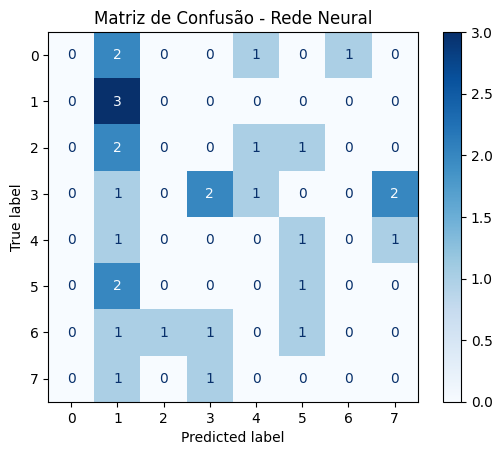

In [ ]:
# treinamento pt4 (MLP route with confusion matrix visualization)

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

matriz = confusion_matrix(y_test, previsoes)

grafico = ConfusionMatrixDisplay(confusion_matrix=matriz)
grafico.plot(cmap='Blues')

plt.title("Matriz de Confusão - Rede Neural")
plt.show()

Aplicada a correção do otimizador para L-BFGS, constatamos a resolução do aviso de convergência, demonstrando que o modelo finalmente conseguiu estabilizar seus cálculos. Contudo, a acurácia permaneceu estagnada nos 20,69%. 

Para investigar a fundo a natureza desse baixo desempenho, resolvemos gerar uma Matriz de Confusão como ferramenta de diagnóstico visual. Ao analisar os resultados, a diagonal principal revelou os acertos exatos do modelo: apenas 3 alunos na nota 1, 2 alunos na nota 3 e 1 aluno na nota 5. O indício do verdadeiro problema, no entanto, revelou-se na coluna vertical correspondente ao rótulo "predicted 1". O MLP previu a nota "1" treze vezes no total, atribuindo-a erroneamente a alunos que, na realidade, tiraram 0, 2, 4, 5, 6 e 7. Além disso, a rede nunca sequer cogitou prever as notas "0" ou "6" para nenhum aluno no conjunto de teste.

Diante desse comportamento anômalo, focamos a atenção na natureza do MLP e do dataset em si. 

O fato matemático: uma rede configurada para receber 30 atributos de entrada e processá-los em uma camada oculta de 15 neurônios exige a calibração simultânea de mais de 450 pesos.

A hipótese: tentar otimizar centenas de parâmetros utilizando 80% da nossa base de 145 instâncias, o equivalente a 116 alunos, fragmentados em 8 categorias do nosso vetor gabarito, seria matemáticamente equivalente a tentar resolver um sistema de 450 variáveis com apenas 116 equações.

A tese: confrontando a elevada capacidade arquitetural da Rede Neural com o pequeno volume do dataset, temos um colapso matemático inerente: o cenário de Data Hunger, que foi abordado anteriormente.

Diante disso e, observando que o modelo previu 13 vezes a nota 1, atribuindo-a de forma errônea a alunos que na realidade tiraram outras notas, observamos que a alternativa adotada pelo modelo foi a de "apelar" para a classe dominante, "chutando-a" de forma repetida para tentar minimizar a margem de erro, um cenário de overfitting.


Não satisfeitos com os resultados, partimos de uma nova premissa teórica: se o MLP possui uma capacidade matemática tão elevada a ponto de ser problemático para lidar com datasets pequenos, faria sentido lógico deduzir que o Single-Layer Perceptron (SLP) — que elimina as Hidden Layers, cortando drasticamente a quantidade de parâmetros e o poder de processamento — nos ofereceria um cenário mais favorável, mitigando o overfitting e aumentando a acurácia global.

Desse modo, configuramos um SLP e testamos nossa premissa. 

In [ ]:
# treinamento pt5 (SLP route)

from sklearn.linear_model import Perceptron

slp = Perceptron(max_iter=1000, random_state=42)

slp.fit(X_train_scaled, y_train)

previsoes_slp = slp.predict(X_test_scaled)
acuracia_slp = accuracy_score(y_test, previsoes_slp)

print(f"Acurácia do Single-Layer Perceptron: {acuracia_slp * 100:.2f}%")

Acurácia do Single-Layer Perceptron: 13.79%


Para a nossa surpresa, obtivemos uma acurácia global ainda menor, de 13,79%, derrubando a nossa teoria inicial.

Para compreender o motivo dessa queda abrupta, revisitamos a página de origem do nosso dataset e atentamo-nos a uma de suas descrições estruturais: "Dataset characteristics: multivariate" (multivariável). Até aquele momento, a nossa análise estava focada exclusivamente no problema do volume de dados (a quantidade de instâncias), mas havíamos negligenciado a complexidade geométrica que a interação entre essas 30 variáveis exigia.

Formulamos, então, uma nova hipótese fundamentada na restrição arquitetural do Perceptron Simples. Ao removermos as camadas ocultas na tentativa de evitar a memorização excessiva, removemos também a capacidade da rede de extrair padrões não-lineares. Pesquisando, descobrimos que matemáticamente o SLP é um modelo rígido, restrito a resolver problemas estritamente lineares. Ele tenta separar as 8 categorias de notas traçando hiperplanos perfeitamente retos em um espaço de 30 dimensões.

No entanto, a relação entre atributos multivariáveis, como a forma que a idade, o tipo de moradia e a posse de bolsa de estudos interagem simultaneamente para afetar a nota final, é repleta de dependências cruzadas e complexas. Os dados não formam grupos geométricos óbvios e separados de forma retilínea. Como o SLP não possui flexibilidade matemática para "dobrar" as suas fronteiras de decisão e mapear essas nuances, ele sofreu do mal diametralmente oposto ao do MLP: o underfitting (subajuste). O modelo tentou impor uma lógica linear crua a um problema de natureza não-linear, entregando um desempenho ainda mais fraco e comprovando que reduzir a arquitetura da rede não compensa a sua incompatibilidade geométrica com a complexidade do dataset.


Diante de sucessivos testes, consolidamos um aprendizado fundamental: o sucesso no treinamento de um modelo de Machine Learning não depende da complexidade isolada do algoritmo, mas do "encaixe" adequado entre a arquitetura do modelo e as características estatísticas do dataset. Escolher um SLP para uma base restrita, porém permeada por variáveis que interagem de forma complexa e não-linear, invariavelmente resulta em subajuste (underfitting), pois o algoritmo não possui a flexibilidade geométrica necessária para mapear esse cenário.

Para validar essa conclusão sobre a dependência intrínseca entre algoritmo e estrutura de dados, e diante do esgotamento das nossas abordagens baseadas em Redes Neurais, decidimos testar uma lógica computacional completamente diferente: a Árvore de Decisão (Decision Tree). Este algoritmo abandona a matemática contínua dos pesos e gradientes em favor de separações lógicas e sequenciais.

A baixa acurácia de 13,79% confirmou, em princípio, a nossa tese. Embora as Árvores de Decisão sejam teoricamente robustas para bases menores e problemas com múltiplas categorias, elas possuem uma fraqueza inerente quando submetidas a matrizes com alta dimensionalidade (30 atributos) e baixíssima densidade de exemplos (116 instâncias diluídas em 8 classes). Sem dados suficientes para estabelecer regras lógicas generalistas, o modelo sofreu um colapso por superajuste (overfitting extremo). A Árvore ramificou-se indefinidamente, criando regras hiperespecíficas até memorizar individualmente cada aluno do conjunto de treino. Ao tentar aplicar essas regras puramente viciadas aos alunos inéditos do conjunto de teste, a capacidade preditiva do modelo desabou."

In [ ]:
# treinamento pt6 (Decision Tree route)
from sklearn.tree import DecisionTreeClassifier

# Instanciando e treinando a Árvore (usamos o X_train original, sem o scaler)
arvore = DecisionTreeClassifier(random_state=42)
arvore.fit(X_train, y_train)

# Avaliando a prova final
previsoes_arvore = arvore.predict(X_test)
acuracia_arvore = accuracy_score(y_test, previsoes_arvore)

print(f"Acurácia da Árvore de Decisão: {acuracia_arvore * 100:.2f}%")

Acurácia da Árvore de Decisão: 13.79%


In [ ]:
# treinamento pt7 (Random Forest route)

from sklearn.ensemble import RandomForestClassifier

# n_estimators=100 cria uma "floresta" com 100 árvores independentes
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

previsoes_rf = rf.predict(X_test)
acuracia_rf = accuracy_score(y_test, previsoes_rf)

print(f"Acurácia do Random Forest: {acuracia_rf * 100:.2f}%")

Acurácia do Random Forest: 17.24%


Para finalizar a linha de raciocínio desta primeira etapa exploratória, concluímos a bateria de testes com o modelo Random Forest. Este algoritmo (ensemble) possui mecanismos naturais para combater o superajuste ao adotar técnicas de aleatorização — como o sorteio de amostras de dados e o fornecimento de subconjuntos de atributos ligeiramente diferentes para cada uma de suas dezenas de árvores, forçando-as a trilhar caminhos de aprendizado distintos e, ao final, decidirem o resultado por votação (Bagging).

Apesar dessa robustez teórica, o resultado de acurácia de 17,24% comprovou de forma definitiva o nosso aprendizado principal: a limitação não residia na escolha das ferramentas, mas na essência matemática da própria base de dados.

Embora a "floresta" tenha mitigado a memorização extrema que derrubou a Árvore de Decisão isolada, ela esbarrou em um limite da teoria da informação: nenhum modelo consegue extrair regras onde não há sinal estruturado. Resgatando novamente a natureza do nosso dataset, como ele fragmenta apenas 116 exemplos em 8 categorias de notas diferentes dentro de um espaço de 30 dimensões, o que a matriz oferece ao algoritmo é puramente ruído estatístico. 

O fato de o modelo prever corretamente apenas 5 alunos no conjunto de teste demonstra uma taxa de acerto perigosamente próxima a um mero chute aleatório. Essa sucessão de falhas validou a conclusão que encerra este bloco: a complexidade algorítmica jamais conseguirá compensar a ausência de densidade estatística e de padrões evidentes nos dados.

Utilização de IA:

1. Ferramenta de validação de hipóteses, mas só depois que elas foram devidamente testadas, exploradas teoricamente e comprovadas.
2. Ferramenta de consulta das funções das bibliotecas utilizadas.
3. Ferramenta de correção gramatical e coesão textual (texto construído totalmente por nós, só mandamos um prompt junto aos textos do tipo: por favor, não altere em absolutamente nada o texto, apenas o corrija gramaticalmente e elementos de coesão textual)